In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Image

candidate_paths = [
    Path("../data/airbnb_london.csv"),
    Path("data/airbnb_london.csv"),
    Path("airbnb_london.csv"),
    Path("listings-28.csv"),
]
data_path = next((p for p in candidate_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "Could not find the London listings CSV. Save it as data/airbnb_london.csv "
        "or place listings-28.csv beside the notebook."
    )

df = pd.read_csv(data_path, low_memory=False)
print(f"Loaded {len(df):,} listings from {data_path}")
print(f"Columns available: {len(df.columns)}")
print(df[["room_type", "price", "reviews_per_month"]].head())


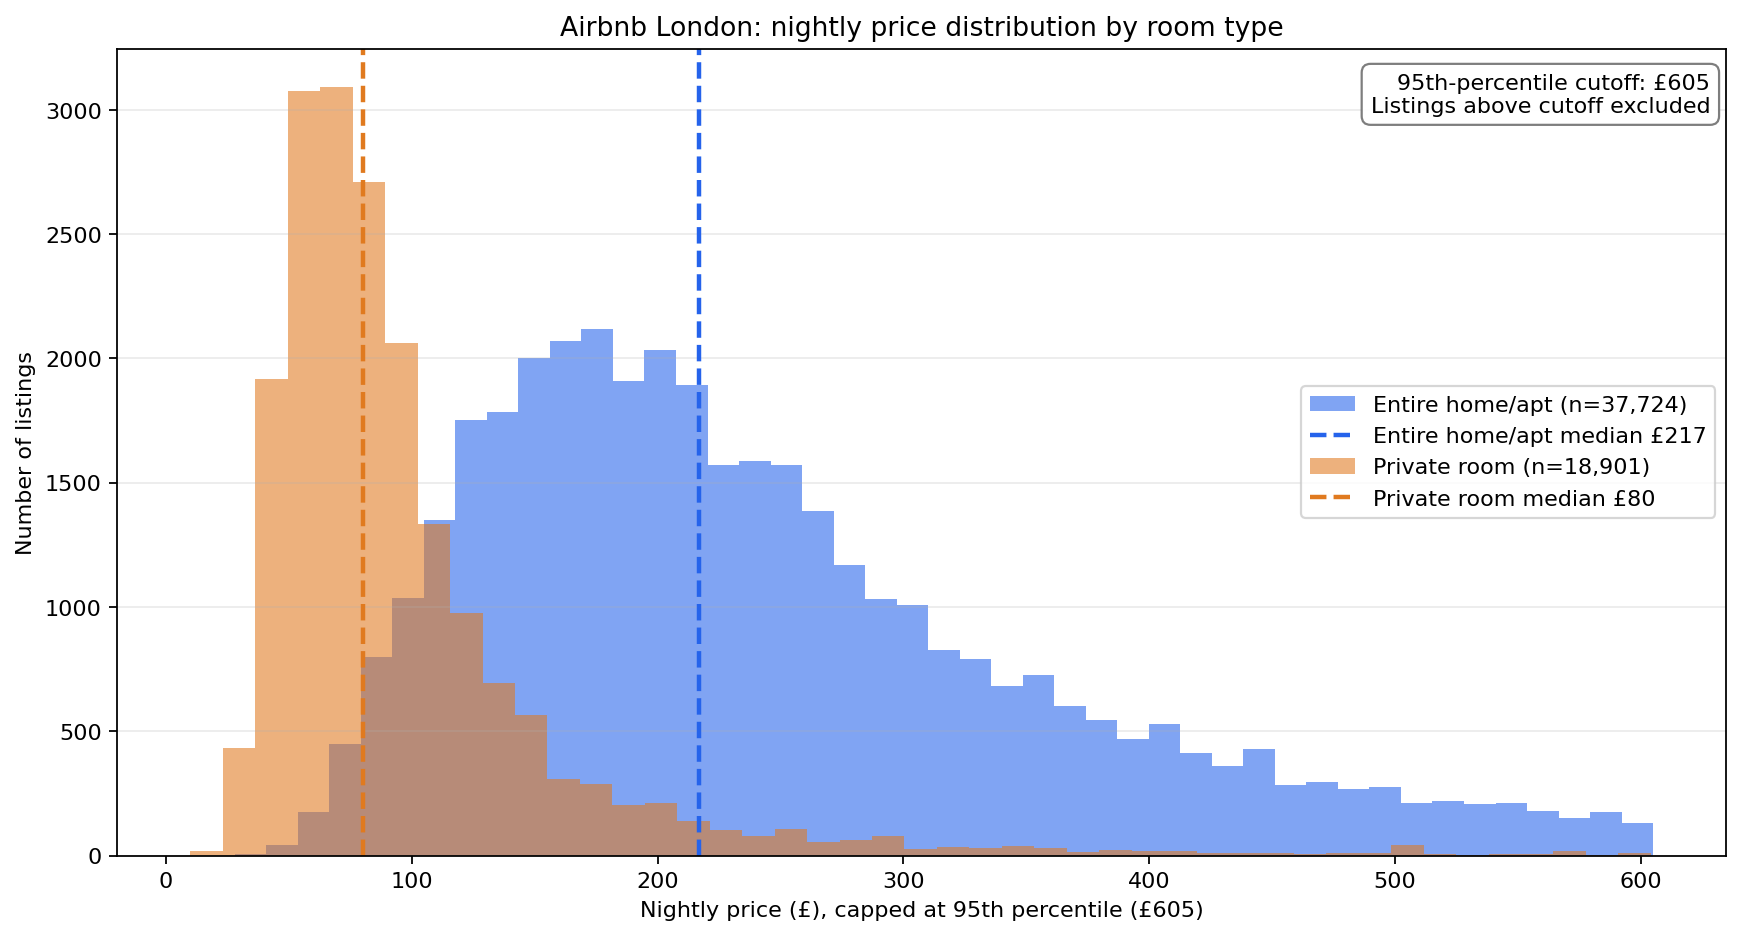

In [3]:
required = {"price", "room_type"}
missing = required - set(df.columns)
if missing:
    raise KeyError(f"Dataset is missing required columns: {sorted(missing)}")

price_df = df.copy()
price_df["price"] = pd.to_numeric(
    price_df["price"].astype(str).str.replace(r"[$£€,]", "", regex=True).str.strip(),
    errors="coerce"
)
price_df = price_df[(price_df["price"] > 0) & price_df["room_type"].notna()]

p95 = price_df["price"].quantile(0.95)
room_order = ["Entire home/apt", "Private room"]
hist_df = price_df[
    (price_df["price"] <= p95) & price_df["room_type"].isin(room_order)
].copy()

if hist_df.empty:
    raise ValueError("No usable price rows found for Entire home/apt and Private room.")

medians = hist_df.groupby("room_type")["price"].median()
counts = hist_df["room_type"].value_counts()
colors = {"Entire home/apt": "#2563EB", "Private room": "#E07A1F"}

fig1, ax1 = plt.subplots(figsize=(11, 6))
for room in room_order:
    values = hist_df.loc[hist_df["room_type"] == room, "price"]
    ax1.hist(values, bins=45, alpha=0.58, color=colors[room],
             label=f"{room} (n={len(values):,})")
    if room in medians.index:
        ax1.axvline(medians[room], color=colors[room], linestyle="--", linewidth=2,
                    label=f"{room} median £{medians[room]:,.0f}")

ax1.set_title("Airbnb London: nightly price distribution by room type")
ax1.set_xlabel(f"Nightly price (£), capped at 95th percentile (£{p95:,.0f})")
ax1.set_ylabel("Number of listings")
ax1.legend(frameon=True)
ax1.grid(axis="y", alpha=0.25)
ax1.text(0.99, 0.97, f"95th-percentile cutoff: £{p95:,.0f}\nListings above cutoff excluded",
         transform=ax1.transAxes, ha="right", va="top",
         bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#777", alpha=0.95))
fig1.tight_layout()
plt.show()

print(f"95th-percentile price cutoff: £{p95:,.2f}")
print("\nMedian price by room type (£):")
print(medians.round(2))
print("\nListings included in histogram:")
print(counts)


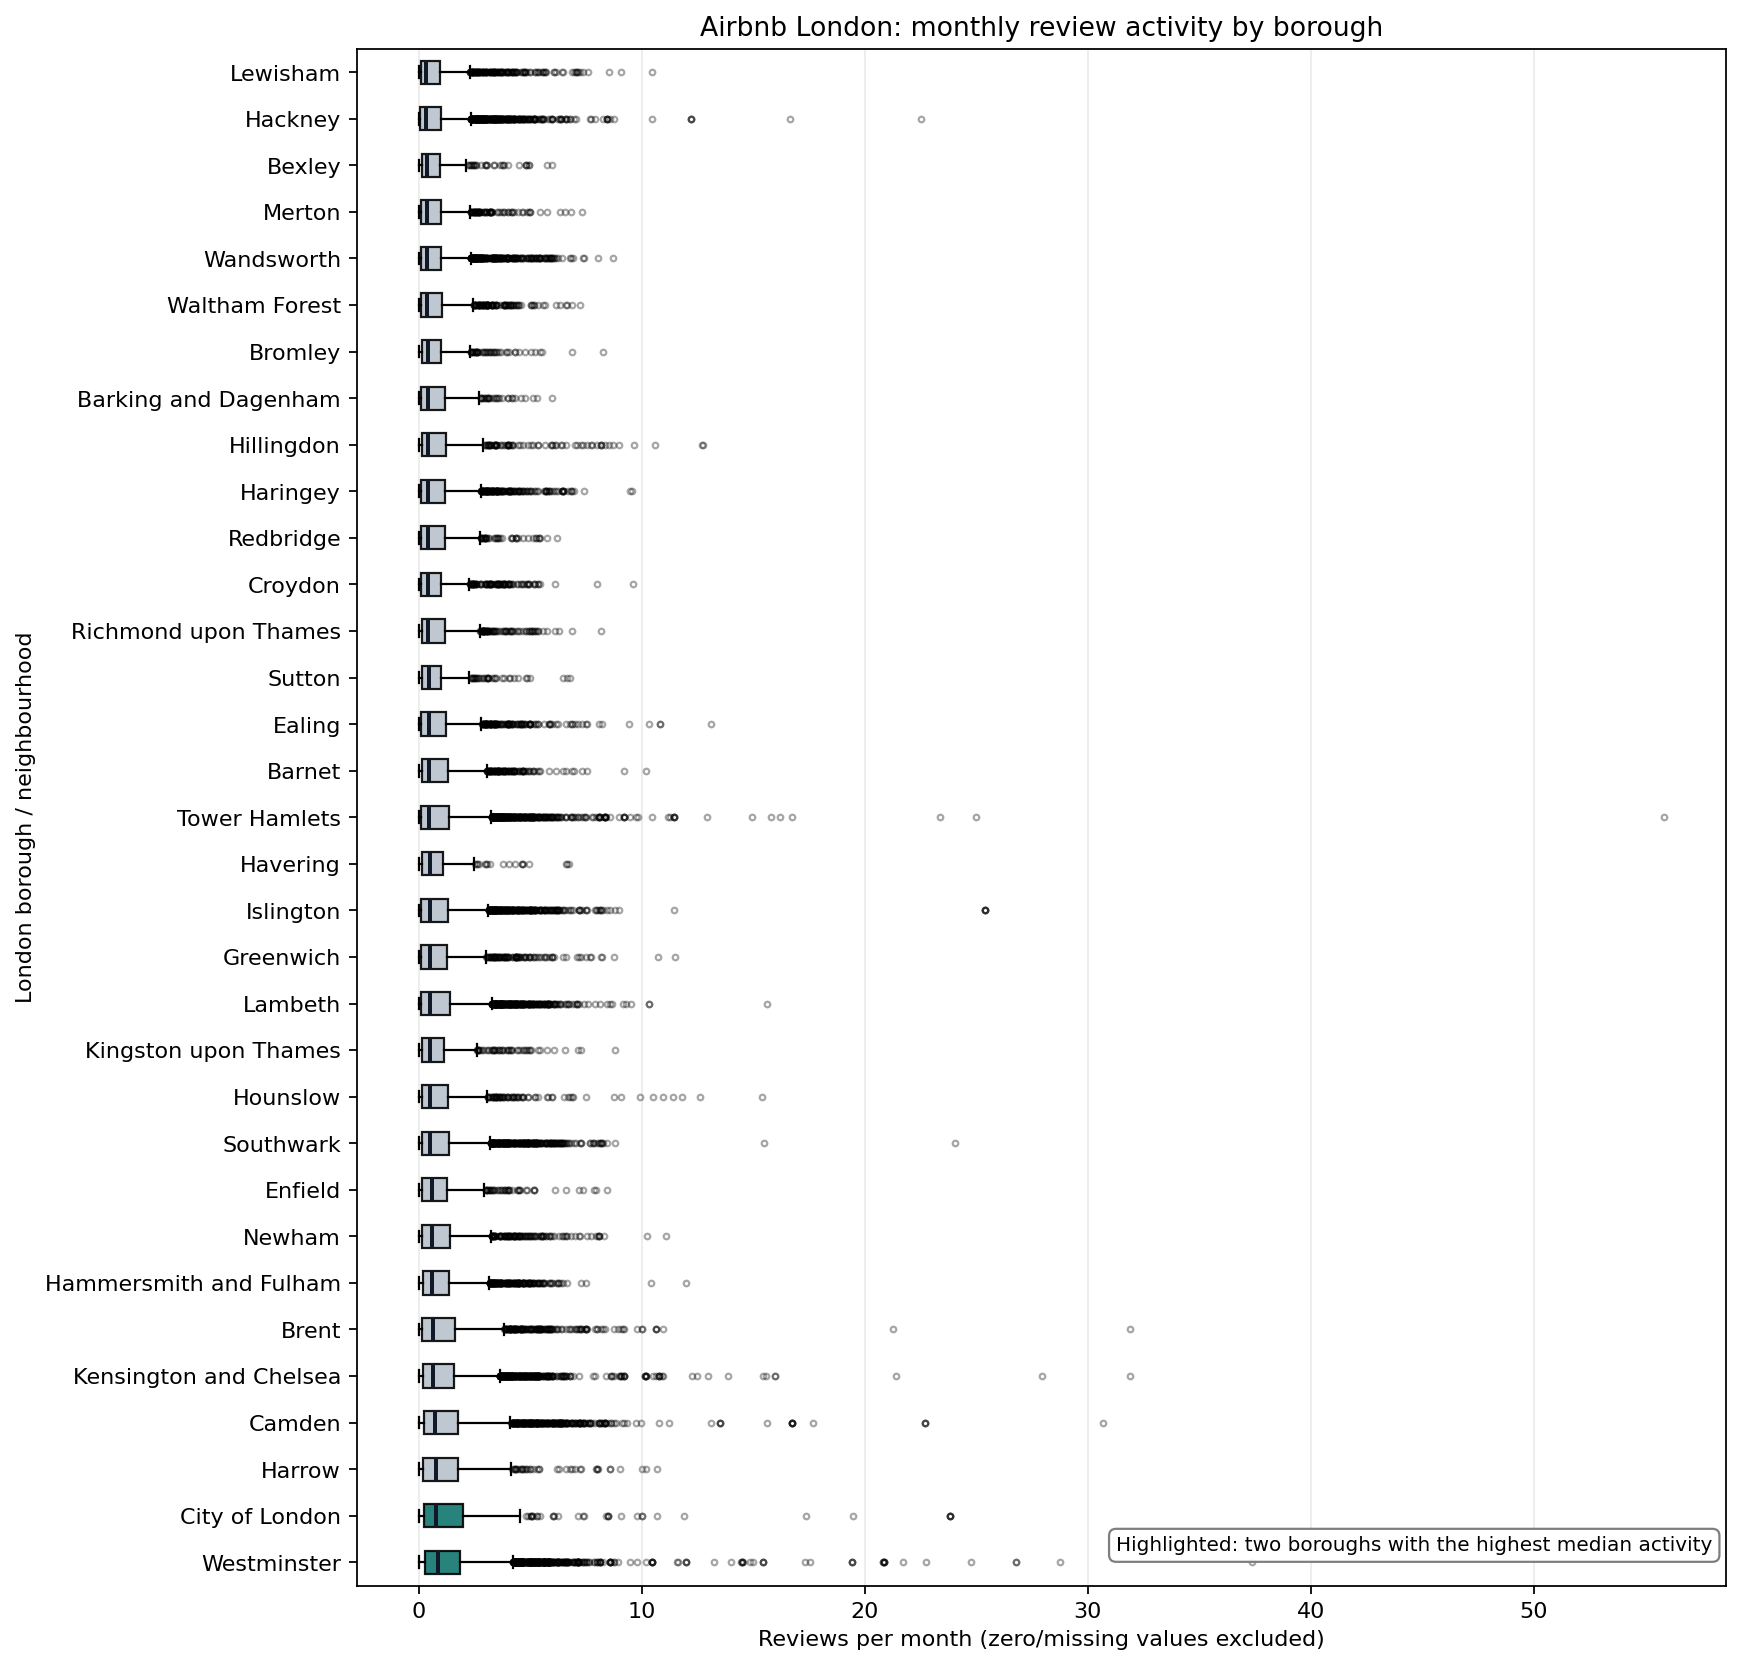

In [5]:
required = {"reviews_per_month"}
missing = required - set(df.columns)
if missing:
    raise KeyError(f"Dataset is missing required columns: {sorted(missing)}")

borough_candidates = ["neighbourhood_cleansed", "neighbourhood", "borough"]
borough_col = next((c for c in borough_candidates if c in df.columns), None)
if borough_col is None:
    raise KeyError("Could not find a borough column. Expected one of: " + ", ".join(borough_candidates))

activity = df[[borough_col, "reviews_per_month"]].copy()
activity["reviews_per_month"] = pd.to_numeric(activity["reviews_per_month"], errors="coerce")
activity = activity.dropna(subset=[borough_col, "reviews_per_month"])
activity = activity[activity["reviews_per_month"] > 0]
activity = activity.rename(columns={borough_col: "borough"})
activity["borough"] = activity["borough"].astype(str).str.strip()
activity = activity[activity["borough"] != ""]

if activity.empty:
    raise ValueError("No listings with positive reviews_per_month values were found.")

borough_medians = activity.groupby("borough")["reviews_per_month"].median().sort_values(ascending=False)
top_two = borough_medians.head(2).index.tolist()
borough_order = borough_medians.index.tolist()

fig2, ax2 = plt.subplots(figsize=(11, max(8, len(borough_order) * 0.32)))
box_data = [activity.loc[activity["borough"] == borough, "reviews_per_month"].values
            for borough in borough_order]
bp = ax2.boxplot(
    box_data, vert=False, labels=borough_order, patch_artist=True, showfliers=True,
    medianprops=dict(color="#111827", linewidth=1.8),
    flierprops=dict(marker="o", markersize=2.5, alpha=0.35)
)
for patch, borough in zip(bp["boxes"], borough_order):
    patch.set_facecolor("#0F766E" if borough in top_two else "#B8C2CC")
    patch.set_alpha(0.9)

ax2.set_title("Airbnb London: monthly review activity by borough")
ax2.set_xlabel("Reviews per month (zero/missing values excluded)")
ax2.set_ylabel("London borough / neighbourhood")
ax2.grid(axis="x", alpha=0.25)
ax2.text(0.99, 0.02, "Highlighted: two boroughs with the highest median activity",
         transform=ax2.transAxes, ha="right", va="bottom",
         bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="#777", alpha=0.95),
         fontsize=9)
fig2.tight_layout()
plt.show()

print("Top two boroughs by median reviews per month:")
print(borough_medians.head(2).round(2))
print(f"Listings included after excluding zero/missing reviews per month: {len(activity):,}")
